In [1]:
'''
CELL 1: MOUNT GOOGLE DRIVE
Connects Colab to your Google Drive so the notebook can read heart.csv.
A popup will ask for permission; click "Allow".
'''
from google.colab import drive                                   # Colab helper to access Google Drive
drive.mount('/content/drive')                                    # Mount Drive (click "Allow" when prompted)

Mounted at /content/drive


In [2]:
'''
CELL 2: IMPORT LIBRARIES
Loads the tools used in this project: pandas and numpy for data,
TensorFlow for the neural network, scikit-learn for splitting, scaling,
and metrics, and matplotlib for plots. Also fixes random seeds so the
results stay the same each run.
'''
import numpy as np                                               # Numerical operations
import pandas as pd                                              # Load and handle the CSV data
import matplotlib.pyplot as plt                                  # Plot training curves
import tensorflow as tf                                          # Deep learning framework (includes Keras)
from sklearn.model_selection import train_test_split             # Split data into train and test sets
from sklearn.preprocessing import StandardScaler                 # Scale features to mean 0, std 1
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix  # Evaluation metrics

np.random.seed(42); tf.random.set_seed(42)                       # Fix random seeds so results are repeatable

In [3]:
'''
CELL 3: LOAD THE DATASET
Reads heart.csv from your Drive folder and shows its size and the
first rows to confirm it loaded correctly.
'''
path = '/content/drive/MyDrive/1. Introduction_to_AI/H_D_Project/heart.csv'  # Path to heart.csv in your Drive folder
df = pd.read_csv(path)                                           # Read the CSV into a DataFrame
print(df.shape)                                                  # Show rows and columns (should be 303, 14)
df.head()                                                        # Display the first 5 rows

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
'''
CELL 4: PREPROCESS THE DATA
Turns categorical columns (like chest pain type) into 0/1 columns,
separates the features (X) from the label (y), splits the data into
80% training and 20% testing, and scales the features so the neural
network trains well.
'''
cat_cols = ['sex','cp','fbs','restecg','exang','slope','ca','thal']   # Categorical columns
df = pd.get_dummies(df, columns=cat_cols, dtype=float)           # One-hot encode the categorical columns
X = df.drop('target', axis=1).values.astype('float32')           # Features: every column except target
y = df['target'].values                                          # Label: 1 = heart disease, 0 = no disease

X_train, X_test, y_train, y_test = train_test_split(             # Split into training and test sets
    X, y, test_size=0.2, random_state=42, stratify=y)            # 80/20 split, keeping the class balance

scaler = StandardScaler()                                        # Create the scaler
X_train = scaler.fit_transform(X_train)                          # Fit on training data only, then scale it
X_test = scaler.transform(X_test)                                # Scale test data with the same settings
print("Train:", X_train.shape, " Test:", X_test.shape)           # Show the size of each set

Train: (242, 30)  Test: (61, 30)


In [5]:
'''
CELL 5: BUILD THE NEURAL NETWORK
Creates a small deep learning model with two hidden layers (32 and 16
neurons), dropout layers to reduce overfitting, and one output neuron
that gives the probability of heart disease.
'''
model = tf.keras.Sequential([                                    # Stack layers one after another
    tf.keras.Input(shape=(X_train.shape[1],)),                   # Input layer: one neuron per feature
    tf.keras.layers.Dense(32, activation='relu'),                # Hidden layer 1: 32 neurons, ReLU activation
    tf.keras.layers.Dropout(0.3),                                # Randomly drop 30% of neurons to reduce overfitting
    tf.keras.layers.Dense(16, activation='relu'),                # Hidden layer 2: 16 neurons, ReLU activation
    tf.keras.layers.Dropout(0.3),                                # Dropout again
    tf.keras.layers.Dense(1, activation='sigmoid')               # Output: probability of heart disease (0 to 1)
])
model.compile(optimizer='adam',                                  # Adam optimizer
              loss='binary_crossentropy',                        # Standard loss for yes/no classification
              metrics=['accuracy'])                              # Track accuracy during training
model.summary()                                                  # Print the network architecture

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
'''
CELL 6: TRAIN THE MODEL
Trains the network on the training data. Early stopping ends training
when validation results stop improving and keeps the best version of
the model.
'''
early_stop = tf.keras.callbacks.EarlyStopping(                   # Stop when validation stops improving
    monitor='val_loss', patience=15, restore_best_weights=True)  # Wait 15 epochs, then keep the best weights
history = model.fit(X_train, y_train,                            # Train on the training data
                    validation_split=0.2,                        # Hold out 20% of training data for validation
                    epochs=200, batch_size=16,                   # Up to 200 passes, 16 samples per update
                    callbacks=[early_stop], verbose=0)           # Use early stopping and hide per-epoch logs
print("Training stopped after", len(history.history['loss']), "epochs")  # Show how many epochs actually ran

Training stopped after 62 epochs


In [7]:
'''
CELL 7: EVALUATE ON THE TEST SET
Tests the trained model on patients it has never seen and prints the
accuracy, the confusion matrix, and precision/recall for each class.
'''
y_prob = model.predict(X_test).ravel()                           # Predicted probabilities for test patients
y_pred = (y_prob > 0.5).astype(int)                              # Convert to class 0/1 using a 0.5 threshold
print(f"Test Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")  # Overall accuracy
print(confusion_matrix(y_test, y_pred))                          # Correct vs. wrong predictions per class
print(classification_report(y_test, y_pred))                     # Precision, recall, and F1 for each class

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
Test Accuracy: 81.97%
[[21  7]
 [ 4 29]]
              precision    recall  f1-score   support

           0       0.84      0.75      0.79        28
           1       0.81      0.88      0.84        33

    accuracy                           0.82        61
   macro avg       0.82      0.81      0.82        61
weighted avg       0.82      0.82      0.82        61



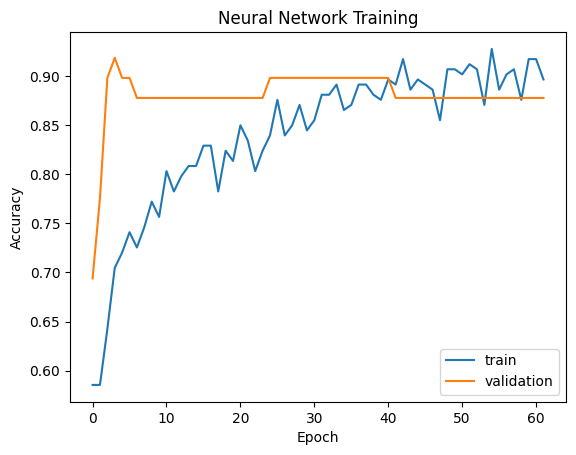

In [8]:
'''
CELL 8: PLOT THE TRAINING CURVES
Draws training and validation accuracy per epoch. If the two lines
stay close together, the model is not overfitting.
'''
plt.plot(history.history['accuracy'], label='train')             # Training accuracy per epoch
plt.plot(history.history['val_accuracy'], label='validation')    # Validation accuracy per epoch
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()        # Axis labels and legend
plt.title('Neural Network Training'); plt.show()                 # Title and display

In [9]:
'''
CELL 10: WEB FRONT END (GRADIO APP)
Builds a web form where you enter a patient's details and get the
model's predicted chance of heart disease. The input is preprocessed
exactly like the training data (one-hot encoding + the same scaler).
The app opens inside Colab and also prints a public link you can
open in a new browser tab.
'''
!pip install -q gradio                                           # Install Gradio (web UI library), quiet mode
import gradio as gr                                              # Import Gradio

feature_cols = df.drop('target', axis=1).columns                 # Column order the model was trained on

def predict_patient(age, sex, cp, trestbps, chol, fbs, restecg,  # Function the app calls when you click Predict
                    thalach, exang, oldpeak, slope, ca, thal):
    row = pd.DataFrame([{                                        # Put the inputs into a one-row table
        'age': age, 'trestbps': trestbps, 'chol': chol,          # Numeric inputs
        'thalach': thalach, 'oldpeak': oldpeak,                  # More numeric inputs
        'sex': int(sex), 'cp': int(cp), 'fbs': int(fbs),         # Categorical inputs as integers
        'restecg': int(restecg), 'exang': int(exang),            # More categorical inputs
        'slope': int(slope), 'ca': int(ca), 'thal': int(thal)}]) # More categorical inputs
    row = pd.get_dummies(row, columns=cat_cols, dtype=float)     # One-hot encode, same as training
    row = row.reindex(columns=feature_cols, fill_value=0)        # Add missing dummy columns as 0, match column order
    row = scaler.transform(row.values.astype('float32'))         # Scale with the scaler fit on training data
    p = float(model.predict(row, verbose=0)[0][0])               # Probability of heart disease
    if p > 0.5:                                                  # Model predicts disease
        msg = f"<h2 style='color:#d9534f'> High risk: {p*100:.1f}%</h2>"   # Red warning message
    else:                                                        # Model predicts no disease
        msg = f"<h2 style='color:#28a745'> Low risk: {p*100:.1f}%</h2>"     # Green reassuring message
    return {"Heart Disease": p, "No Heart Disease": 1 - p}, msg  # Return values for both output boxes

with gr.Blocks(theme=gr.themes.Soft(), title="Heart Disease Predictor") as app:  # Create the app with a soft theme
    gr.Markdown("#  Heart Disease Prediction\n"                # Page title
                "Enter the patient's details and click **Predict**. "  # Instructions
                "_For learning purposes only, not medical advice._")   # Disclaimer
    with gr.Row():                                               # Put the input columns side by side
        with gr.Column():                                        # Left column: numeric values
            age      = gr.Slider(20, 80, value=54, step=1, label="Age (years)")                # Age slider
            trestbps = gr.Slider(90, 200, value=130, step=1, label="Resting Blood Pressure (mm Hg)")  # BP slider
            chol     = gr.Slider(120, 570, value=240, step=1, label="Cholesterol (mg/dl)")     # Cholesterol slider
            thalach  = gr.Slider(70, 205, value=150, step=1, label="Max Heart Rate Achieved")  # Max heart rate slider
            oldpeak  = gr.Slider(0.0, 6.5, value=1.0, step=0.1, label="ST Depression (oldpeak)")  # ST depression slider
            ca       = gr.Slider(0, 4, value=0, step=1, label="Number of Major Vessels (0-4)")  # Vessel count slider
        with gr.Column():                                        # Right column: category choices
            sex     = gr.Radio([("Male", 1), ("Female", 0)], value=1, label="Sex")             # Sex choice
            cp      = gr.Dropdown([("Typical angina", 0), ("Atypical angina", 1),
                                   ("Non-anginal pain", 2), ("Asymptomatic", 3)],
                                  value=0, label="Chest Pain Type")                           # Chest pain type
            fbs     = gr.Radio([("No", 0), ("Yes", 1)], value=0, label="Fasting Blood Sugar > 120 mg/dl")  # Blood sugar
            restecg = gr.Dropdown([("Normal", 0), ("ST-T abnormality", 1),
                                   ("Left ventricular hypertrophy", 2)],
                                  value=1, label="Resting ECG")                               # Resting ECG result
            exang   = gr.Radio([("No", 0), ("Yes", 1)], value=0, label="Exercise-Induced Angina")  # Angina during exercise
            slope   = gr.Dropdown([("Upsloping", 0), ("Flat", 1), ("Downsloping", 2)],
                                  value=1, label="Slope of Peak Exercise ST")                 # ST slope
            thal    = gr.Dropdown([("Unknown", 0), ("Fixed defect", 1), ("Normal", 2),
                                   ("Reversible defect", 3)], value=2, label="Thalassemia")  # Thal result
    btn = gr.Button("🔍 Predict", variant="primary")             # Big blue Predict button
    with gr.Row():                                               # Outputs side by side
        result_msg   = gr.HTML()                                 # Coloured risk message
        result_probs = gr.Label(label="Prediction Probabilities") # Bar chart of both probabilities
    btn.click(predict_patient,                                   # When the button is clicked, run the function
              inputs=[age, sex, cp, trestbps, chol, fbs, restecg,
                      thalach, exang, oldpeak, slope, ca, thal], # Inputs in the same order as the function
              outputs=[result_probs, result_msg])                # Where the results go

app.launch(share=True)                                           # Start the app in Colab and print a public link

/tmp/ipykernel_1793/595489628.py:32: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(), title="Heart Disease Predictor") as app:  # Create the app with a soft theme


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d5632cb2dd4c925864.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [10]:
'''
CELL 10: ADVANCED WEB FRONT END (GRADIO APP)
A multi-tab dashboard for the heart disease neural network:
  1. Single Patient: form, risk gauge, probability bars,
     "what drives this prediction" chart, sample patients, history log
  2. Batch Prediction: upload a CSV of patients, get predictions, download results
  3. Model Insights: training curves, confusion matrix, test accuracy
  4. About: what each input means
Run Cells 1-9 first so the model, scaler and data are in memory.
'''
!pip install -q gradio                                           # Install Gradio (web UI library), quiet mode
import gradio as gr                                              # Import Gradio

# ---------- Setup: data, column info, friendly names ----------
raw = pd.read_csv(path)                                          # Reload the original (un-encoded) data
feature_cols = df.drop('target', axis=1).columns                 # Column order the model was trained on
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']     # Numeric input columns
names = {'age': 'Age', 'trestbps': 'Resting BP', 'chol': 'Cholesterol',      # Friendly names for charts
         'thalach': 'Max Heart Rate', 'oldpeak': 'ST Depression', 'sex': 'Sex',
         'cp': 'Chest Pain Type', 'fbs': 'Fasting Blood Sugar', 'restecg': 'Resting ECG',
         'exang': 'Exercise Angina', 'slope': 'ST Slope', 'ca': 'Major Vessels', 'thal': 'Thalassemia'}
baseline = {c: raw[c].median() if c in num_cols else raw[c].mode()[0]       # "Typical patient": median of numbers,
            for c in num_cols + cat_cols}                                   # most common value of categories

# ---------- Helper functions ----------
def prep(data):                                                  # Preprocess any table of patients like training data
    d = data[num_cols + cat_cols].copy()                         # Keep only the 13 input columns
    d[cat_cols] = d[cat_cols].astype(int)                        # Make sure categories are whole numbers
    d = pd.get_dummies(d, columns=cat_cols, dtype=float)         # One-hot encode categories
    d = d.reindex(columns=feature_cols, fill_value=0)            # Add missing dummy columns, match column order
    return scaler.transform(d.values.astype('float32'))          # Scale with the training scaler

def prob(data):                                                  # Get disease probabilities for a table of patients
    return model.predict(prep(data), verbose=0).ravel()          # Run the neural network and flatten the output

def gauge(p):                                                    # Draw a coloured risk bar with a pointer
    fig, ax = plt.subplots(figsize=(6, 1.4))                     # Small wide figure
    ax.barh(0, 0.3, color='#2ecc71')                             # Green zone: 0-30% (low)
    ax.barh(0, 0.3, left=0.3, color='#f1c40f')                   # Yellow zone: 30-60% (moderate)
    ax.barh(0, 0.4, left=0.6, color='#e74c3c')                   # Red zone: 60-100% (high)
    ax.plot([p, p], [-0.5, 0.5], color='black', lw=5)            # Black pointer at the patient's risk
    ax.set_xlim(0, 1); ax.set_yticks([])                         # 0-1 axis, hide the y axis
    ax.set_xticks([0, .3, .6, 1]); ax.set_xticklabels(['0%', '30%', '60%', '100%'])  # Percentage tick labels
    ax.set_title(f'Risk score: {p*100:.1f}%', fontweight='bold') # Title with the exact score
    plt.tight_layout(); plt.close(fig); return fig               # Tidy up, stop Colab double-display, return

def contrib_plot(row, p):                                        # Show which inputs raise or lower the risk
    alts = pd.DataFrame([{**row, c: baseline[c]} for c in baseline])   # 13 copies, each with one input set to "typical"
    d = p - prob(alts)                                           # Risk change caused by this patient's actual value
    labels = np.array([names[c] for c in baseline])              # Friendly feature names
    order = np.argsort(np.abs(d))                                # Sort from smallest to largest effect
    fig, ax = plt.subplots(figsize=(6, 4.5))                     # Figure for the chart
    ax.barh(labels[order], d[order] * 100,                       # Horizontal bars, effect in percentage points
            color=['#e74c3c' if v > 0 else '#2ecc71' for v in d[order]])   # Red = raises risk, green = lowers
    ax.axvline(0, color='gray', lw=1)                            # Zero line
    ax.set_xlabel('Effect on risk (percentage points vs. typical patient)')  # Axis label
    ax.set_title('What drives this prediction?', fontweight='bold')          # Chart title
    plt.tight_layout(); plt.close(fig); return fig               # Tidy up and return

def predict_patient(age, sex, cp, trestbps, chol, fbs, restecg,  # Called when "Predict" is clicked
                    thalach, exang, oldpeak, slope, ca, thal, log):
    row = dict(age=age, sex=sex, cp=cp, trestbps=trestbps, chol=chol, fbs=fbs,   # Collect the inputs
               restecg=restecg, thalach=thalach, exang=exang, oldpeak=oldpeak,
               slope=slope, ca=ca, thal=thal)
    p = float(prob(pd.DataFrame([row]))[0])                      # Predicted probability of heart disease
    level, color = (('High', '#e74c3c') if p >= 0.6 else         # Pick the risk level and colour
                    ('Moderate', '#f39c12') if p >= 0.3 else ('Low', '#27ae60'))
    msg = (f"<div class='card' style='border-left:8px solid {color}'>"     # Styled result card
           f"<h2 style='color:{color};margin:0'>{level} risk</h2>"         # Risk level heading
           f"<p style='font-size:18px'>Estimated probability of heart disease: <b>{p*100:.1f}%</b></p></div>")
    log = log + [{**row, 'Risk %': round(p * 100, 1), 'Level': level}]     # Add this patient to the history
    return (msg, {'Heart Disease': p, 'No Heart Disease': 1 - p},          # Return card and probability bars,
            gauge(p), contrib_plot(row, p), pd.DataFrame(log), log)        # gauge, drivers chart, history table, state

def predict_batch(file):                                         # Called when "Predict All" is clicked
    if file is None:                                             # No file uploaded
        return None, ' Please upload a CSV file first.', None   # Show a warning
    data = pd.read_csv(file if isinstance(file, str) else file.name)       # Read the uploaded CSV
    missing = [c for c in num_cols + cat_cols if c not in data.columns]   # Check the required columns exist
    if missing:                                                  # Some columns are missing
        return None, f' Missing columns: {missing}', None       # Tell the user which ones
    data['Risk %'] = (prob(data) * 100).round(1)                 # Predict every patient
    data['Prediction'] = np.where(data['Risk %'] > 50, 'Disease', 'No disease')   # Turn into a label
    info = f"Predicted **{len(data)}** patients. "             # Summary message
    if 'target' in data.columns:                                 # If true answers are included...
        acc = ((data['Risk %'] > 50).astype(int) == data['target']).mean() * 100  # ...compute the accuracy
        info += f"Accuracy against the `target` column: **{acc:.1f}%**"           # Add it to the message
    out = '/content/predictions.csv'; data.to_csv(out, index=False)        # Save results for download
    return data, info, out                                       # Table, message, downloadable file

# ---------- Model insight figures (made once) ----------
train_fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))      # Two side-by-side charts
a1.plot(history.history['accuracy'], label='train')              # Training accuracy
a1.plot(history.history['val_accuracy'], label='validation')     # Validation accuracy
a1.set_title('Accuracy'); a1.set_xlabel('Epoch'); a1.legend()    # Labels
a2.plot(history.history['loss'], label='train')                  # Training loss
a2.plot(history.history['val_loss'], label='validation')         # Validation loss
a2.set_title('Loss'); a2.set_xlabel('Epoch'); a2.legend()        # Labels
plt.tight_layout(); plt.close(train_fig)                         # Tidy and stop double display

cm = confusion_matrix(y_test, y_pred)                            # Confusion matrix from Cell 7 predictions
cm_fig, ax = plt.subplots(figsize=(4.5, 4))                      # Figure for the matrix
ax.imshow(cm, cmap='Blues')                                      # Draw as a blue heatmap
for i in range(2):                                               # Loop over rows
    for j in range(2):                                           # Loop over columns
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=18)   # Write each count in its square
ax.set_xticks([0, 1]); ax.set_xticklabels(['No disease', 'Disease'])     # Predicted-class labels
ax.set_yticks([0, 1]); ax.set_yticklabels(['No disease', 'Disease'])     # Actual-class labels
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Confusion Matrix (test set)')
plt.tight_layout(); plt.close(cm_fig)                            # Tidy and stop double display
test_acc = accuracy_score(y_test, y_pred) * 100                  # Test accuracy in percent

css = """
#title {text-align:center}
.card {padding:16px; border-radius:12px; background:#fafafa; box-shadow:0 2px 8px rgba(0,0,0,.08)}
"""                                                              # Custom styling for the title and result card

# ---------- Build the app ----------
with gr.Blocks(theme=gr.themes.Soft(primary_hue='red'), css=css, title='Heart Disease Predictor') as app:
    gr.Markdown("# ❤️ Heart Disease Risk Dashboard\n"            # Page title
                "Neural network trained on the UCI heart dataset. "
                "_For learning purposes only, not medical advice._", elem_id='title')
    log_state = gr.State([])                                     # Stores the prediction history for this session

    with gr.Tabs():                                              # Start the tab layout
        # ===== Tab 1: Single patient =====
        with gr.Tab('🩺 Single Patient'):
            with gr.Row():                                       # Inputs on the left, results on the right
                with gr.Column(scale=1):                         # Input column
                    with gr.Accordion('Vital signs', open=True): # Collapsible group for numeric values
                        age      = gr.Slider(20, 80, value=54, step=1, label='Age (years)')
                        trestbps = gr.Slider(90, 200, value=130, step=1, label='Resting Blood Pressure (mm Hg)')
                        chol     = gr.Slider(120, 570, value=240, step=1, label='Cholesterol (mg/dl)')
                        thalach  = gr.Slider(70, 205, value=150, step=1, label='Max Heart Rate Achieved')
                        sex      = gr.Radio([('Male', 1), ('Female', 0)], value=1, label='Sex')
                        fbs      = gr.Radio([('No', 0), ('Yes', 1)], value=0, label='Fasting Blood Sugar > 120 mg/dl')
                    with gr.Accordion('Clinical tests', open=True):   # Collapsible group for test results
                        cp      = gr.Dropdown([('Typical angina', 0), ('Atypical angina', 1),
                                               ('Non-anginal pain', 2), ('Asymptomatic', 3)],
                                              value=0, label='Chest Pain Type')
                        restecg = gr.Dropdown([('Normal', 0), ('ST-T abnormality', 1),
                                               ('Left ventricular hypertrophy', 2)], value=1, label='Resting ECG')
                        exang   = gr.Radio([('No', 0), ('Yes', 1)], value=0, label='Exercise-Induced Angina')
                        oldpeak = gr.Slider(0.0, 6.5, value=1.0, step=0.1, label='ST Depression (oldpeak)')
                        slope   = gr.Dropdown([('Upsloping', 0), ('Flat', 1), ('Downsloping', 2)],
                                              value=1, label='Slope of Peak Exercise ST')
                        ca      = gr.Slider(0, 4, value=0, step=1, label='Number of Major Vessels (0-4)')
                        thal    = gr.Dropdown([('Unknown', 0), ('Fixed defect', 1), ('Normal', 2),
                                               ('Reversible defect', 3)], value=2, label='Thalassemia')
                    predict_btn = gr.Button('🔍 Predict Risk', variant='primary', size='lg')  # Main button
                with gr.Column(scale=1):                         # Results column
                    result_card  = gr.HTML("<div class='card'>Fill in the form and click <b>Predict Risk</b>.</div>")
                    gauge_plot   = gr.Plot(label='Risk Gauge')    # Coloured risk bar
                    result_probs = gr.Label(label='Prediction Probabilities')   # Probability bars
                    drivers_plot = gr.Plot(label='Key Drivers')   # What-drives-the-prediction chart

            inputs = [age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal]  # All inputs
            gr.Examples(examples=[[63, 1, 3, 145, 233, 1, 0, 150, 0, 2.3, 0, 0, 1],    # Sample patients from the dataset
                                  [67, 1, 0, 160, 286, 0, 0, 108, 1, 1.5, 1, 3, 2],
                                  [41, 0, 1, 130, 204, 0, 0, 172, 0, 1.4, 2, 0, 2]],
                        inputs=inputs, label='Try a sample patient (click a row to fill the form)')
            with gr.Accordion('📜 Prediction history', open=False):  # Collapsible history section
                history_table = gr.Dataframe(label='Patients checked this session')   # History table
                clear_btn = gr.Button('🗑️ Clear history')         # Button to reset the history

            predict_btn.click(predict_patient, inputs=inputs + [log_state],          # Run prediction on click
                              outputs=[result_card, result_probs, gauge_plot,
                                       drivers_plot, history_table, log_state])
            clear_btn.click(lambda: (pd.DataFrame(), []), outputs=[history_table, log_state])  # Empty the history

        # ===== Tab 2: Batch prediction =====
        with gr.Tab('📂 Batch Prediction'):
            gr.Markdown('Upload a CSV with the same columns as `heart.csv` '   # Instructions
                        '(the `target` column is optional; if present, accuracy is shown).')
            csv_in    = gr.File(label='Upload CSV', file_types=['.csv'])        # File upload box
            batch_btn = gr.Button('🚀 Predict All', variant='primary')          # Batch predict button
            batch_msg = gr.Markdown()                                           # Summary message
            batch_tbl = gr.Dataframe(label='Results')                           # Results table
            batch_out = gr.File(label='Download results')                       # Downloadable CSV
            batch_btn.click(predict_batch, inputs=csv_in, outputs=[batch_tbl, batch_msg, batch_out])  # Wire up

        # ===== Tab 3: Model insights =====
        with gr.Tab('📊 Model Insights'):
            gr.Markdown(f"### Test accuracy: **{test_acc:.1f}%** on {len(y_test)} unseen patients\n"
                        f"Architecture: {X_train.shape[1]} inputs → 32 → 16 → 1 (ReLU, Dropout 0.3, Sigmoid output)")
            gr.Plot(value=train_fig, label='Training curves')    # Accuracy and loss over epochs
            gr.Plot(value=cm_fig, label='Confusion matrix')      # Correct vs. wrong on the test set

        # ===== Tab 4: About =====
        with gr.Tab('ℹ️ About'):
            gr.Markdown("""
| Input | Meaning |
|---|---|
| Age | Age in years |
| Resting BP | Resting blood pressure (mm Hg) |
| Cholesterol | Serum cholesterol (mg/dl) |
| Max Heart Rate | Highest heart rate reached during exercise |
| ST Depression | Change in ECG during exercise compared with rest |
| Chest Pain Type | Type of chest pain the patient feels |
| Fasting Blood Sugar | Whether fasting blood sugar is above 120 mg/dl |
| Resting ECG | Result of the resting electrocardiogram |
| Exercise Angina | Chest pain caused by exercise |
| ST Slope | Shape of the ECG ST segment at peak exercise |
| Major Vessels | Number of major vessels seen in fluoroscopy (0-4) |
| Thalassemia | Result of the thallium stress test |

**Key Drivers chart:** each bar shows how much the patient's risk changes because of that input,
compared with a typical patient from the dataset. Red bars raise the risk; green bars lower it.
""")                                                             # Explanation table

app.launch(share=True, debug=False)                              # Start the app in Colab and print a public link

/tmp/ipykernel_1793/2643955869.py:119: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(primary_hue='red'), css=css, title='Heart Disease Predictor') as app:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://79a87b561e2ba64083.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
